# Example 1.3 — Transmission Angle Analysis
**Four Bar Mechanisms: Synthesis with Genetic Algorithms and Neural Networks**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)

---
## Statement
For the four-bar mechanism with the following dimensions:

| Link | Length |
|---------|----------|
| Crank $a$ | 50 mm |
| Coupler $b$ | 120 mm |
| Rocker $c$ | 80 mm |
| Frame $d$ | 100 mm |

**Calculate the transmission angle $\mu$ for each crank position** $\theta_2 \in [0°, 360°]$ and determine:
1. The minimum and maximum transmission angle.
2. The positions where the mechanism operates outside the optimal zone ($45° < \mu < 135°$).
3. A plot of the behavior of $\mu(	heta_2)$.

---
## Theoretical foundation

The **transmission angle** $\mu$ is the angle at joint $B$ between the coupler and the rocker.
A value of $\mu$ close to 90° guarantees maximum force transfer; extreme values
($\mu < 40°$ or $\mu > 140°$) indicate positions of poor transmission.

From the **vector loop**, we obtain the diagonal $e$ of the quadrilateral formed by the crank and frame:

$$e^2 = a^2 + d^2 - 2ad\cos\theta_2 \tag{1.4}$$

Applying the law of cosines to the triangle formed by $b$, $c$ and $e$:

$$\cos\mu = \frac{b^2 + c^2 - e^2}{2bc} \tag{1.5}$$

**Optimal operating zone:** $45° \leq \mu \leq 135°$

## Calculation of transmission angle

Equations **(1.4)** and **(1.5)** are applied directly for the entire range of $\theta_2$.

In [12]:
from numpy import *

# --- Mechanism parameters ---
a, b, c, d = 50., 120., 80., 100.   # mm

# --- Crank sweep ---
th2 = linspace(0, 2*pi, 360, endpoint=False)  # 360 positions

# --- Eq. (1.4): diagonal e of the crank-frame quadrilateral ---
e2 = a**2 + d**2 - 2*a*d*cos(th2)   # e² (mm²)

# --- Eq. (1.5): transmission angle μ ---
cos_mu = (b**2 + c**2 - e2) / (2*b*c)
cos_mu = clip(cos_mu, -1.0, 1.0)    # numerical caution
mu_rad = arccos(cos_mu)              # rad
mu_deg = degrees(mu_rad)             # degrees

# --- Statistics ---
idx_min = argmin(mu_deg)
idx_max = argmax(mu_deg)
outside_low = sum(mu_deg < 45.)
outside_high = sum(mu_deg > 135.)
in_zone    = sum((mu_deg >= 45.) & (mu_deg <= 135.))

print("=== Transmission Angle Analysis ===")
print(f"Dimensions: a={a:.0f} mm  b={b:.0f} mm  c={c:.0f} mm  d={d:.0f} mm")
print(f"\nMinimum transmission angle : {mu_deg[idx_min]:.2f}°  at θ₂ = {degrees(th2[idx_min]):.1f}°")
print(f"Maximum transmission angle : {mu_deg[idx_max]:.2f}° at θ₂ = {degrees(th2[idx_max]):.1f}°")
print(f"\nPositions outside the optimal zone (μ < 45° or μ > 135°):")
print(f"  μ < 45°  : {outside_low} positions ({100*outside_low/360:.1f}% of the cycle)")
print(f"  μ > 135° : {outside_high} positions ({100*outside_high/360:.1f}% of the cycle)")
print(f"\nPositions in optimal zone (45° ≤ μ ≤ 135°): {in_zone} / 360 ({100*in_zone/360:.1f}%)")

=== Transmission Angle Analysis ===
Dimensions: a=50 mm  b=120 mm  c=80 mm  d=100 mm

Minimum transmission angle : 17.61°  at θ₂ = 0.0°
Maximum transmission angle : 95.08° at θ₂ = 180.0°

Positions outside the optimal zone (μ < 45° or μ > 135°):
  μ < 45°  : 117 positions (32.5% of the cycle)
  μ > 135° : 0 positions (0.0% of the cycle)

Positions in optimal zone (45° ≤ μ ≤ 135°): 243 / 360 (67.5%)


## Display

The following cell generates two graphs:
- **Left:** diagram of the mechanism at position $\theta_2 = 90°$ with transmission angle $\mu$ marked at point $B$.
- **Right:** $\mu(\theta_2)$ curve with the optimal zone shaded in green.

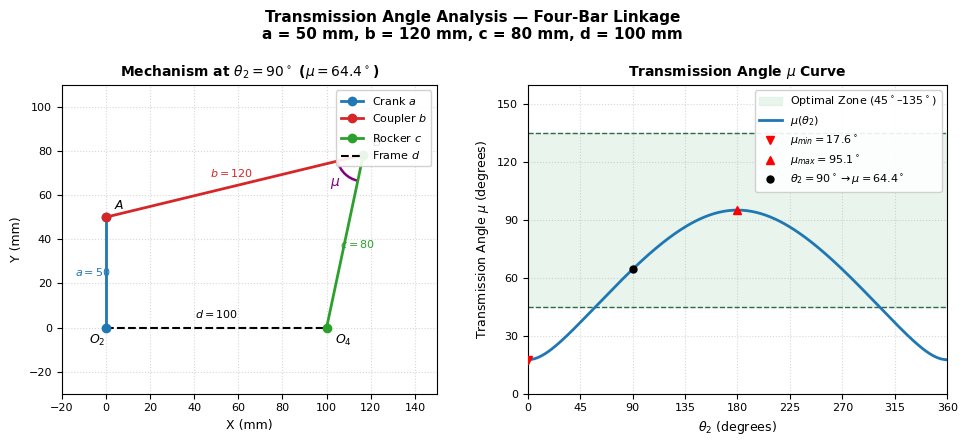

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Springer Technical Configurations ─────────────────────────────────────────
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans', 'sans-serif']

# Dynamic naming block based on requirements
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_1_3_transmission_angle"
except Exception:
    notebook_name = "Figure_1_3_transmission_angle"

# ── Recalculate with standard numpy for display ──────────────────────────────
a_, b_, c_, d_ = 50., 120., 80., 100.
th2_ = np.linspace(0, 2*np.pi, 360, endpoint=False)
e2_  = a_**2 + d_**2 - 2*a_*d_*np.cos(th2_)
cos_mu_ = np.clip((b_**2 + c_**2 - e2_) / (2*b_*c_), -1., 1.)
mu_deg_ = np.degrees(np.arccos(cos_mu_))

# Position of the mechanism at θ₂ = 90° for the diagram
def fourbar_th4(a, b, c, d, th2_val):
    K1 = d/a; K2 = d/c; K3 = (a**2 - b**2 + c**2 + d**2)/(2*a*c)
    A = np.cos(th2_val) - K1 - K2*np.cos(th2_val) + K3
    B = -2*np.sin(th2_val)
    C = K1 - (K2+1)*np.cos(th2_val) + K3
    disc = B**2 - 4*A*C
    if disc < 0:
        return np.nan
    return 2*np.arctan2(-B - np.sqrt(disc), 2*A)

th2_demo = np.radians(90.)
th4_demo = fourbar_th4(a_, b_, c_, d_, th2_demo)

O2 = np.array([0., 0.])
O4 = np.array([d_, 0.])
A_pt = np.array([a_*np.cos(th2_demo), a_*np.sin(th2_demo)])
B_pt = np.array([d_ + c_*np.cos(th4_demo), c_*np.sin(th4_demo)])

# Vectors from B towards A and towards O4 for the angle μ
v_BA = A_pt - B_pt
v_BO4 = O4 - B_pt
angle_BA  = np.degrees(np.arctan2(v_BA[1], v_BA[0]))
angle_BO4 = np.degrees(np.arctan2(v_BO4[1], v_BO4[0]))

# ── Figure Setup (Springer Compact Layout) ───────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

# ── Left panel: mechanism diagram ────────────────────────────────────────────
ax1.plot(*zip(O2, A_pt), color='#1f77b4', marker='o', lw=2, ms=6, zorder=5, label='Crank $a$')
ax1.plot(*zip(A_pt, B_pt), color='#d62728', marker='o', lw=2, ms=6, zorder=5, label='Coupler $b$')
ax1.plot(*zip(B_pt, O4), color='#2ca02c', marker='o', lw=2, ms=6, zorder=5, label='Rocker $c$')
ax1.plot(*zip(O2, O4), 'k--', lw=1.5, label='Frame $d$')

# Arc of angle μ at point B
arc = mpatches.Arc(B_pt, 24, 24,
                   angle=0,
                   theta1=min(angle_BA, angle_BO4),
                   theta2=max(angle_BA, angle_BO4),
                   color='purple', lw=1.8)
ax1.add_patch(arc)

# Label μ next to arc
ang_mid = np.radians((angle_BA + angle_BO4) / 2)
mu_label_pos = B_pt + 18*np.array([np.cos(ang_mid), np.sin(ang_mid)])
ax1.text(mu_label_pos[0], mu_label_pos[1], r'$\mu$',
         fontsize=10, color='purple', fontweight='bold', ha='center', va='center')

# Node labels with optimized offsets to prevent overlap
offsets = {'$O_2$': (-12, -12), '$A$': (6, 6), '$B$': (6, 6), '$O_4$': (6, -12)}
for pt, lbl, off in zip([O2, A_pt, B_pt, O4],
                         list(offsets.keys()),
                         list(offsets.values())):
    ax1.annotate(lbl, pt, xytext=off, textcoords='offset points',
                 fontsize=9, fontweight='bold')

# Length dimensions (proportional placement)
for pt1, pt2, lbl, col in [
    (O2, A_pt, f'$a={a_:.0f}$', '#1f77b4'),
    (A_pt, B_pt, f'$b={b_:.0f}$', '#d62728'),
    (B_pt, O4,  f'$c={c_:.0f}$', '#2ca02c'),
    (O2, O4,    f'$d={d_:.0f}$', 'black')
]:
    mid = (pt1 + pt2) / 2
    v = pt2 - pt1
    n = np.array([-v[1], v[0]]); n = n/np.linalg.norm(n)
    ax1.text(*(mid + 6*n), lbl, fontsize=8, color=col, ha='center', va='center')

ax1.set_xlabel('X (mm)', fontsize=9)
ax1.set_ylabel('Y (mm)', fontsize=9)
ax1.set_title(r'Mechanism at $\theta_2 = 90^\circ$ ($\mu = 64.4^\circ$)', fontsize=10, fontweight='bold')
ax1.legend(fontsize=8, loc='upper right', frameon=True, framealpha=0.9)
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.set_aspect('equal')
ax1.set_xlim(-20, 150)
ax1.set_ylim(-30, 110)
ax1.tick_params(labelsize=8)

# ── Right panel: μ(θ₂) curve ──────────────────────────────────────────────────
th2_deg_ = np.degrees(th2_)

# Optimal shaded area - fixed raw string formatting for label to avoid SyntaxWarning
ax2.axhspan(45, 135, color='#d4edda', alpha=0.5, label=r'Optimal Zone ($45^\circ$–$135^\circ$)')
ax2.axhline(45,  color='#2d6a4f', lw=1, ls='--')
ax2.axhline(135, color='#2d6a4f', lw=1, ls='--')

# μ(θ₂) curve
ax2.plot(th2_deg_, mu_deg_, color='#1f77b4', lw=2, label=r'$\mu(\theta_2)$')

# Critical points marking - fixed raw f-strings (fr) to avoid backslash escaping issues
idx_min_ = np.argmin(mu_deg_)
idx_max_ = np.argmax(mu_deg_)
ax2.plot(th2_deg_[idx_min_], mu_deg_[idx_min_], 'rv', ms=6, zorder=6,
         label=fr'$\mu_{{min}} = {mu_deg_[idx_min_]:.1f}^\circ$')
ax2.plot(th2_deg_[idx_max_], mu_deg_[idx_max_], 'r^', ms=6, zorder=6,
         label=fr'$\mu_{{max}} = {mu_deg_[idx_max_]:.1f}^\circ$')
ax2.plot(th2_deg_[90], mu_deg_[90], 'ko', ms=5, zorder=6,
         label=fr'$\theta_2=90^\circ \rightarrow \mu={mu_deg_[90]:.1f}^\circ$')

ax2.set_xlabel(r'$\theta_2$ (degrees)', fontsize=9)
ax2.set_ylabel(r'Transmission Angle $\mu$ (degrees)', fontsize=9)
ax2.set_title(r'Transmission Angle $\mu$ Curve', fontsize=10, fontweight='bold')
ax2.set_xlim(0, 360)
ax2.set_ylim(0, 160)
ax2.set_xticks(range(0, 361, 45))
ax2.set_yticks(range(0, 151, 30))
ax2.legend(fontsize=8, loc='upper right', frameon=True, framealpha=0.9)
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.tick_params(labelsize=8)

plt.suptitle('Transmission Angle Analysis — Four-Bar Linkage\n'
             'a = 50 mm, b = 120 mm, c = 80 mm, d = 100 mm',
             fontsize=11, fontweight='bold')
plt.tight_layout()

# ── Double Format Export ─────────────────────────────────────────────────────
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()